# 01 · Exploração do DriverMHG

Contagens e durações usam as listas oficiais, com todas as pessoas. As tiras de frames usam uma única gravação (pessoa 1, gravação 1), a primeira que baixamos.

**Licença:** documentos publicados podem ter no máximo 10 frames e 2 clipes sem aprovação da TUM. Por isso as tiras são gravadas em `data/interno/`, fora do git, e não ficam embutidas neste notebook.

In [1]:
import os, sys
from pathlib import Path
if Path.cwd().name == "notebooks":
    os.chdir("..")
sys.path.insert(0, "src")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from PIL import Image
import drivermhg as M
pd.set_option("display.max_rows", 100, "display.width", 140)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": "#e4e3df",
                     "axes.titlelocation": "left", "axes.titleweight": "bold", "figure.dpi": 110})
BASE = Path("data/DriverMHG")
PASTA_ANOTACAO = BASE / "anotacao/media/kop/760E6E913CA0F70B/PC_backup/datasets/DriverMHG/Annotation"
GRAVACAO = BASE / "amostra/media/kop/760E6E913CA0F70B/PC_backup/datasets/DriverMHG/Subject1/Rec1"
RESULTADOS = Path("resultados"); RESULTADOS.mkdir(exist_ok=True)
INTERNO = Path("data/interno"); INTERNO.mkdir(exist_ok=True)

## Contagem por classe e divisão

A divisão é a oficial: pessoas 1-18 no treino e 19-25 no teste.

In [2]:
anot = M.ler_listas(PASTA_ANOTACAO)
print("Segmentos:", len(anot), "| pessoas:", anot.pessoa.nunique())
print("Pessoas no treino:", sorted(anot[anot.subconjunto == "treino"].pessoa.unique()))
print("Pessoas no teste:", sorted(anot[anot.subconjunto == "teste"].pessoa.unique()))
assert not set(anot[anot.subconjunto == "treino"].pessoa) & set(anot[anot.subconjunto == "teste"].pessoa)
por_classe = anot.pivot_table(index=["gesto", "mao"], columns="subconjunto", values="inicio", aggfunc="count")
por_classe["total"] = por_classe.sum(axis=1)
por_classe.to_csv(RESULTADOS / "drivermhg_por_classe.csv")
por_classe

Segmentos: 5148 | pessoas: 25
Pessoas no treino: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18)]
Pessoas no teste: [np.int64(19), np.int64(20), np.int64(21), np.int64(22), np.int64(23), np.int64(24), np.int64(25)]


subconjunto          teste  treino  total
gesto      mao                           
FlickDown  direita     100     257    357
           esquerda    104     259    363
FlickUp    direita     102     262    364
           esquerda    105     268    373
None       direita     107     269    376
           esquerda    107     270    377
Other      direita     106     264    370
           esquerda    106     263    369
SwipeLeft  direita     100     266    366
           esquerda    104     267    371
SwipeRight direita     101     260    361
           esquerda    100     266    366
Tap        direita     102     266    368
           esquerda    102     265    367

Nos segmentos anotados, as classes são equilibradas. `None` e `Other` têm o mesmo peso dos gestos, então uma acurácia alta nesses recortes diz pouco sobre o uso contínuo.

## Contagem por pessoa

In [3]:
por_pessoa = anot.groupby(["pessoa", "subconjunto"]).agg(segmentos=("inicio", "count"), gravacoes=("gravacao", "nunique")).reset_index()
por_pessoa.to_csv(RESULTADOS / "drivermhg_por_pessoa.csv", index=False)
print(por_pessoa.segmentos.describe().round(1).to_string())
por_pessoa

count     25.0
mean     205.9
std        6.0
min      186.0
25%      204.0
50%      207.0
75%      209.0
max      214.0


,pessoa,subconjunto,segmentos,gravacoes
0,1,treino,210,5
1,2,treino,210,5
2,3,treino,209,5
3,4,treino,209,5
4,5,treino,207,5
5,6,treino,201,5
6,7,treino,206,5
7,8,treino,209,5
8,9,treino,204,5
9,10,treino,210,5


## Frames por gesto

A 30 fps, cada frame equivale a 33 ms.

Média geral: 28.1 frames = 0.94 s
subconjunto
teste     30.3
treino    27.3


,count,mean,median,min,max,media_s
gesto,,,,,,
FlickDown,720,30.4,30.0,8,64,1.01
FlickUp,737,28.9,29.0,4,61,0.96
None,753,28.1,28.0,7,56,0.94
Other,739,29.8,29.0,5,63,0.99
SwipeLeft,737,29.0,28.0,8,59,0.97
SwipeRight,727,30.4,30.0,10,62,1.01
Tap,735,20.3,19.0,5,53,0.68


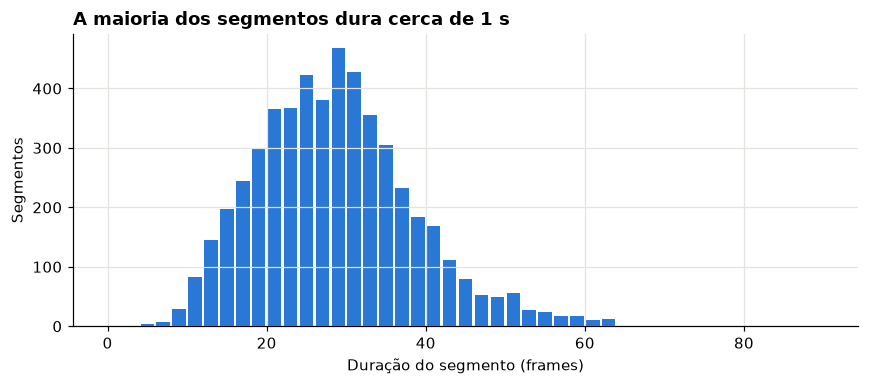

In [4]:
duracao = anot.groupby("gesto").n_frames.agg(["count", "mean", "median", "min", "max"]).round(1)
duracao["media_s"] = (duracao["mean"] / M.FPS).round(2)
duracao.to_csv(RESULTADOS / "drivermhg_duracao.csv")
print("Média geral:", round(anot.n_frames.mean(), 1), "frames =", round(anot.n_frames.mean() / M.FPS, 2), "s")
print(anot.groupby("subconjunto").n_frames.mean().round(1).to_string())
display(duracao)
fig, eixo = plt.subplots(figsize=(8, 3.6))
eixo.hist(anot.n_frames, bins=range(0, 91, 2), color="#2a78d6", rwidth=0.85)
eixo.set_xlabel("Duração do segmento (frames)"); eixo.set_ylabel("Segmentos")
eixo.set_title("A maioria dos segmentos dura cerca de 1 s")
fig.tight_layout(); fig.savefig("figuras/drivermhg_duracao.png", dpi=200); plt.show()

Os segmentos do teste são um pouco mais longos que os do treino, o que pode indicar diferença entre as pessoas ou no jeito de anotar. É bom levar isso em conta ao escolher a janela temporal.

## A gravação como fluxo contínuo

No uso real não há recortes: o modelo roda o tempo todo. Aqui medimos quanto de uma gravação fica sem anotação. Esses intervalos são a base disponível para estimar falsos disparos.

In [5]:
seq = M.ler_anotacao_gravacao(GRAVACAO)
n_frames = len(list((GRAVACAO / "rgb").glob("*.jpg")))
marcados = np.zeros(n_frames, dtype=bool)
for s in seq.itertuples():
    marcados[s.inicio:s.fim + 1] = True
gestos = seq[~seq.gesto.isin(["None", "Other"])]
print("Frames:", n_frames, "=", round(n_frames / M.FPS), "s")
print("Segmentos:", len(seq), "| gestos:", len(gestos), "| None + Other:", len(seq) - len(gestos))
print("Sem anotação:", int((~marcados).sum()), "frames =", round((~marcados).mean() * 100, 1), "% da gravação =", round((~marcados).sum() / M.FPS), "s")
print("Tempo entre gestos: mediana", round(gestos.inicio.diff().median() / M.FPS, 1), "s")
seq.head(10)

Frames: 5201 = 173 s
Segmentos: 42 | gestos: 30 | None + Other: 12
Sem anotação: 3681 frames = 70.8 % da gravação = 123 s
Tempo entre gestos: mediana 5.6 s


,classe,gesto,mao,inicio,fim
0,11,None,direita,0,35
1,12,None,esquerda,83,113
2,1,FlickDown,direita,113,146
3,11,None,direita,210,250
4,3,SwipeLeft,direita,254,282
5,12,None,esquerda,295,340
6,14,Other,esquerda,358,387
7,10,Tap,esquerda,420,448
8,13,Other,direita,450,469
9,2,FlickUp,direita,590,620


Esses números valem para uma gravação só. A contagem do teste inteiro depende do download completo.

## Tiras de frames de cada gesto

Uma imagem por classe, com dois exemplos e 8 frames por exemplo, em RGB e infravermelho. As imagens ficam em `data/interno/`.

In [6]:
def salvar_tira(classe, modalidade="rgb", exemplos=2, frames=8):
    amostras = seq[seq.classe == classe].head(exemplos)
    fig, eixos = plt.subplots(len(amostras), frames, figsize=(frames * 2, 1.6 * len(amostras)), squeeze=False)
    for i, s in enumerate(amostras.itertuples()):
        for j in range(frames):
            f = s.inicio + (s.fim - s.inicio) * j // (frames - 1)
            eixos[i][j].imshow(Image.open(GRAVACAO / modalidade / f"{f:05d}.jpg"))
            eixos[i][j].axis("off"); eixos[i][j].set_title(str(f), fontsize=7)
    gesto, mao = M.nome_classe(classe)
    fig.suptitle(f"{gesto}, mão {mao} ({modalidade})"); fig.tight_layout()
    caminho = INTERNO / f"{classe:02d}_{gesto}_{mao}_{modalidade}.png"
    fig.savefig(caminho, dpi=90); plt.close(fig)
    return caminho

caminhos = [salvar_tira(c, m) for c in range(1, 15) for m in ("rgb", "ir")]
print(len(caminhos), "tiras em", INTERNO)

28 tiras em data\interno


## O que levar daqui

- **Divisão por pessoa:** as listas oficiais não têm nenhuma pessoa em comum entre treino e teste.
- **Gestos muito sutis:** a câmera filma de frente para o volante, as mãos são pequenas e o volante gira durante a direção. O movimento do gesto pode ser menor que o da própria direção.
- **Inversão horizontal proibida:** o README oficial avisa que ela troca a classe de alguns gestos.
- **Ainda sem confirmação:** a conferência visual da numeração das classes.